In [145]:
import string
import random
from random import randint
import cv2
import numpy as np
import os
from ipywidgets import interact
from PIL import Image, ImageFont, ImageDraw
import matplotlib.pyplot as plt

# Generate perfect images

In [146]:
# Run this command only once:

# makes the output folder /content/pictures/
!mkdir pictures

mkdir: cannot create directory ‘pictures’: File exists


In [147]:
# Run this command only once

# Downloads the license plate template to /content/blank_plate.png
!gdown 1Q_FsX2z6DaDCLM91qGZzwvctaW9bN60v

Downloading...
From: https://drive.google.com/uc?id=1Q_FsX2z6DaDCLM91qGZzwvctaW9bN60v
To: /content/blank_plate.png
100% 144k/144k [00:00<00:00, 74.9MB/s]


In [148]:
path = "/content/"

NUMBER_OF_PLATES = 100

# Generate NUMBER_OF_PLATES with random values of the form CC NN (C: character
# N: number)

for i in range(0, NUMBER_OF_PLATES):

    # Pick two random letters
    plate_alpha = ""
    for _ in range(0, 2):
        plate_alpha += (random.choice(string.ascii_uppercase))

    # Pick two random numbers
    num = randint(0, 99)
    plate_num = "{:02d}".format(num)

    # Write plate to image
    blank_plate = cv2.imread(path+'blank_plate.png')

    # Convert into a PIL image (this is so we can use the monospaced fonts)
    blank_plate_pil = Image.fromarray(blank_plate)

    # Get a drawing context
    draw = ImageDraw.Draw(blank_plate_pil)
    monospace = ImageFont.truetype(font="/usr/share/fonts/truetype/liberation/LiberationMono-Regular.ttf",
                                   size=165)
    draw.text(xy=(48, 75),
              text=plate_alpha + " " + plate_num,
              fill=(255,0,0), font=monospace)

    # Convert back to OpenCV image and save
    blank_plate = np.array(blank_plate_pil)

    # Write license plate to file
    cv2.imwrite(os.path.join(path + "pictures/",
                             "plate_{}{}.png".format(plate_alpha, plate_num)),
                             blank_plate)

# --My Code--

In [149]:
# Crop and "setup" license plate images in a given folder
#
# input: path to a folder containing license plate image files of the form "plate_XXXX.png"
# return: a list of cropped images of each character in each licence plate; another list containing the corresponding character values

# notes: the character values will be in one-hot format; the images RGB values (0-255) will be normalized (0-1)

def cropped_images(path):

  # map all possible characters to an integer value
  value_map = {
      "A": 0,  "B": 1,  "C": 2,  "D": 3,  "E": 4,  "F": 5,
      "G": 6,  "H": 7,  "I": 8,  "J": 9,  "K": 10, "L": 11,
      "M": 12, "N": 13, "O": 14, "P": 15, "Q": 16, "R": 17,
      "S": 18, "T": 19, "U": 20, "V": 21, "W": 22, "X": 23,
      "Y": 24, "Z": 25,
      "0": 26, "1": 27, "2": 28, "3": 29, "4": 30,
      "5": 31, "6": 32, "7": 33, "8": 34, "9": 35
  }

  # list of all filenames "plate_XXXX.png"
  filenames = os.listdir(path)

  # get dimensions of the images
  firstPlate = np.array(Image.open(path + filenames[0]))
  height = firstPlate.shape[0]
  width = firstPlate.shape[1]

  # define character locations in the image (left, right, top, bottom)
  char_width = int(0.17 * width)
  char_height = int(0.5 * height)
  char_vertical_midpoint = int(0.54 * height)
  char_horizontal_midpoints = [int(0.16 * width), int(0.325 * width), int(0.66 * width), int(0.82 * width)]


  # retrieve character images alongside their values
  character_images = []
  character_values = []
  for i in range(len(filenames)):
        plate = np.array(Image.open(path + filenames[i]))
        for j in range(4):
          top = char_vertical_midpoint - char_height // 2
          bottom = char_vertical_midpoint + char_height // 2
          left = char_horizontal_midpoints[j] - char_width // 2
          right = char_horizontal_midpoints[j] + char_width // 2
          character_images.append(plate[top:bottom, left:right])
          character_values.append(value_map[filenames[i][j + 6]])

  # convert mapped character values to one-hot format (took this from the example code)
  character_values_OH = np.eye(36)[np.array(character_values).reshape(-1)]

  # normalize the pixel values in the cropped images (0-255 --> 0-1)
  character_images_NORM = np.array(character_images, dtype='float32') / 255.0

  return character_images_NORM, character_values_OH


In [150]:
# generate cropped photos and OH character values for all plates in "pictures" folder
folder = "/content/pictures/"

character_images, character_values = cropped_images(folder)

# TEST CROPPING QUALITY --------------------

print("Total character images:", len(character_images))
print("Image data shape:", np.array(character_images).shape)
print("One-hot data shape:", character_values.shape)

def displayImage(index=0):
    print("Character value:", character_values[index])
    print("Image shape:", character_images[index].shape)
    print("One-hot values:", character_values[index])

    plt.figure(figsize=(4, 4))
    plt.imshow(character_images[index])
    plt.show()

interact(displayImage, index=(0, len(character_images) - 1));

Total character images: 908
Image data shape: (908, 148, 102, 3)
One-hot data shape: (908, 36)


interactive(children=(IntSlider(value=0, description='index', max=907), Output()), _dom_classes=('widget-inter…

In [151]:
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.utils import plot_model

# define the sequence of actions performed during one forward pass of this CNN
# (this model is simpler than the cats+dogs model)

conv_model = models.Sequential()
conv_model.add(layers.Conv2D(16, (3, 3), activation='relu', input_shape = character_images[0].shape)) # replaced cats+dogs shape with my image shape
conv_model.add(layers.MaxPooling2D((2, 2)))
conv_model.add(layers.Conv2D(32, (3, 3), activation='relu'))
conv_model.add(layers.MaxPooling2D((2, 2)))
conv_model.add(layers.Flatten())
conv_model.add(layers.Dropout(0.5)) # randomly "drop" values to prevent biases
conv_model.add(layers.Dense(32, activation='relu')) # neuron layers
conv_model.add(layers.Dense(36, activation='softmax')) # condense into 36 possible outputs, instead of 2 from cats+dogs example

conv_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 146, 100, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 73, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 71, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 35, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 26880)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 26880)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │       860,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 36)             │         1,188 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 866,468 (3.31 MB)

 Trainable params: 866,468 (3.31 MB)

 Non-trainable params: 0 (0.00 B)

In [152]:
# reinitialize all weights, biases (I used random number from [-1,1] in the previous lab)
# Source: https://stackoverflow.com/questions/63435679
def reset_weights_tf2(model):
  for ix, layer in enumerate(model.layers):
      if (hasattr(model.layers[ix], 'kernel_initializer') and
          hasattr(model.layers[ix], 'bias_initializer')):
          weight_initializer = model.layers[ix].kernel_initializer
          bias_initializer = model.layers[ix].bias_initializer

          old_weights, old_biases = model.layers[ix].get_weights()

          model.layers[ix].set_weights([
              weight_initializer(shape=old_weights.shape),
              bias_initializer(shape=len(old_biases))])

reset_weights_tf2(conv_model)

# set the learning rate and loss function definiton (categorical_crossentropy); compile CNN
LEARNING_RATE = 1e-4
conv_model.compile(loss='categorical_crossentropy',
                   optimizer=optimizers.RMSprop(learning_rate=LEARNING_RATE),
                   metrics=['acc'])

# train model
history_conv = conv_model.fit(character_images,
                              character_values, # y values (one-hot lists of 36 bits)
                              validation_split=0.2,
                              epochs=10,
                              batch_size=16)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 179ms/step - acc: 0.2025 - loss: 3.1798 - val_acc: 0.2912 - val_loss: 2.6963
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 229ms/step - acc: 0.5537 - loss: 2.1934 - val_acc: 0.6429 - val_loss: 1.6989
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 20s 226ms/step - acc: 0.7273 - loss: 1.3990 - val_acc: 0.7912 - val_loss: 1.0626
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 176ms/step - acc: 0.8182 - loss: 0.8479 - val_acc: 0.8352 - val_loss: 0.6465
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 187ms/step - acc: 0.9022 - loss: 0.4894 - val_acc: 0.9835 - val_loss: 0.3434
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 211ms/step - acc: 0.9559 - loss: 0.2551 - val_acc: 1.0000 - val_loss: 0.1441
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 192ms/step - acc: 0.9793 - loss: 0.1273 - val_acc: 0.9835 - val_loss: 0.0639
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 186ms/step - acc: 0.9972 - loss: 0.0508 - val_acc: 1.0000 - val_loss: 0.0172
Epoch 9/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 207ms/ste

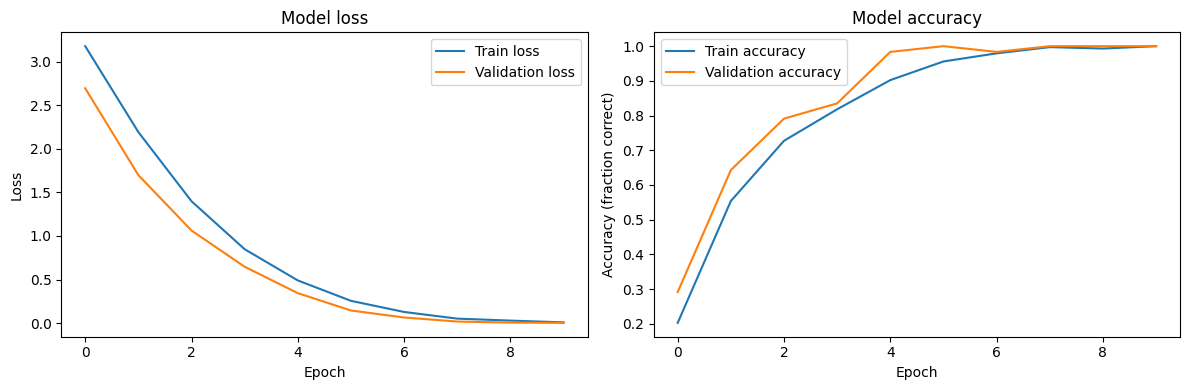

In [153]:
# loss accounts for the confidence. Ie: On a "B" image, "80% B" has lower LOSS than "10% B"
# Accuracy is merely the amount of correct predictions, even if the confidence is only 51%, for example.

# Left: loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_conv.history['loss'])
plt.plot(history_conv.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train loss', 'Validation loss'])

# Right: accuracy
plt.subplot(1, 2, 2)
plt.plot(history_conv.history['acc'])
plt.plot(history_conv.history['val_acc'])
plt.title('Model accuracy')
plt.ylabel('Accuracy (fraction correct)')
plt.xlabel('Epoch')
plt.legend(['Train accuracy', 'Validation accuracy'])

plt.tight_layout()
plt.show()

# Download and uncompress test set

In [154]:
%%capture
!gdown 18TBwgykqhpCoyn6Sf6lV_-MplhIP9R5d
!unzip -n /content/test_pictures.zip

# --More of My Code--

In [155]:
# generate cropped photos and OH character values for all plates in "test_pictures" folder
folder = "/content/test_pictures/"

test_character_images, test_character_values = cropped_images(folder)

print("Total test character images:", len(test_character_images))
print("Image data shape:", test_character_images.shape)
print("One-hot data shape:", test_character_values.shape)

def displayTestImage(index=0):
    print("Character value:", np.argmax(test_character_values[index]))
    print("Image shape:", test_character_images[index].shape)
    print("One-hot values:", test_character_values[index])

    plt.figure(figsize=(4, 4))
    plt.imshow(test_character_images[index])
    plt.show()

interact(displayTestImage, index=(0, len(test_character_images) - 1));

Total test character images: 400
Image data shape: (400, 148, 102, 3)
One-hot data shape: (400, 36)


interactive(children=(IntSlider(value=0, description='index', max=399), Output()), _dom_classes=('widget-inter…

In [156]:
# get the model predictions on these new test images
predictions = conv_model.predict(test_character_images)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step


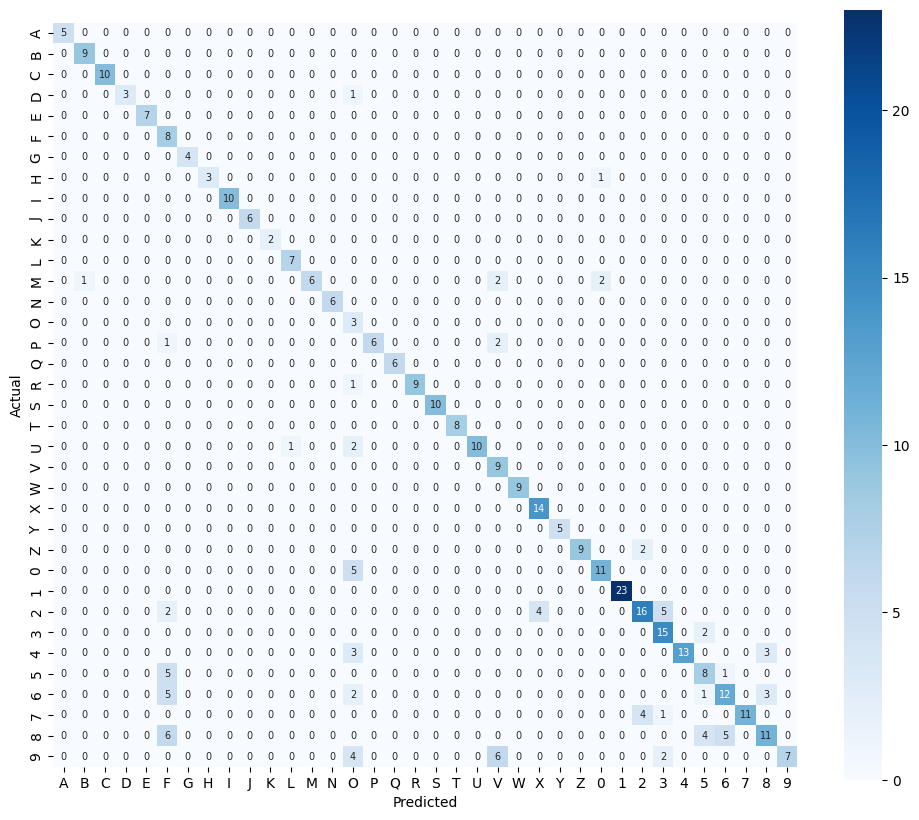

In [163]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Generate a confusion matrix
actual_values = np.argmax(test_character_values, axis=1)
predicted_values = np.argmax(predictions, axis=1)
cm = confusion_matrix(actual_values, predicted_values, labels=range(36))
character_names = list(string.ascii_uppercase + string.digits)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=character_names,
    yticklabels=character_names,
    annot_kws={'size': 7},
    square=True
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [162]:
print(f"Test accuracy: {np.trace(cm) / cm.sum():.1%}")

Test accuracy: 77.8%


# Example of Data Generator

In [158]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import numpy as np

In [159]:
# Load image:
image_path = '/content/pictures/plate_MB42.png'
# Create an array with a single image (we need it for the iterator)
image_array = np.expand_dims(Image.open(image_path), 0)

In [160]:
datagen = ImageDataGenerator(rotation_range=3, zoom_range=0.01,
                             brightness_range=[0.4, 1.0])

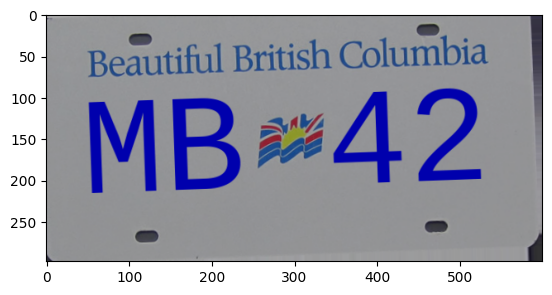

In [161]:
NUM_IMAGES_TO_GENERATE = 1

datagen_iterator = datagen.flow(image_array, batch_size=1)

for j in range(NUM_IMAGES_TO_GENERATE):
  value = next(datagen_iterator)
  img = value[0].astype('uint8')
  plt.imshow(img)